# From FASTQ to fragments

Every single-cell ATAC analysis in Epione starts from a **fragment file**: one line per
Tn5-cut DNA fragment, `chrom  start  end  barcode  count`, bgzip-compressed and
tabix-indexed. Cell Ranger ATAC writes one, but you can make it yourself from the
FASTQs with `epi.upstream.fastq_to_fragments`. That helps when Cell Ranger is not an
option (licence, non-10x chemistry, other genomes, cluster limits), or when you want
to control the aligner and the filters.

The steps are the same whatever the aligner:

1. **Barcode extraction.** 10x scATAC has three reads per fragment: `R1` and `R3` are
   genomic, `R2` (the i5 index read) holds the 16-bp cell barcode. Multiome ATAC has a
   24-bp `R2`: an 8-bp spacer, then the barcode. Depending on the sequencer the barcode
   read comes out forward or reverse-complemented, so Epione checks the first 200 000
   reads against the whitelist in both orientations.
2. **Barcode correction.** A barcode on the whitelist is kept. Otherwise every whitelist
   barcode one substitution away is a candidate. Each candidate is weighted by how often
   it was seen exactly in the run (the prior) times the error probability of the
   differing base, from its quality score. The best candidate is accepted when its
   posterior is at least 0.975. This is the scheme Cell Ranger documents.
3. **Alignment** of the read pairs, keeping pairs where both mates have MAPQ ≥ 30 and
   form a proper pair with an insert of at most 2 kb.
4. **Tn5 shift.** Tn5 inserts as a dimer with a 9-bp stagger, so the cut site is +4 bp
   from the 5′ end of the forward read and −5 bp from the 5′ end of the reverse read.
5. **Duplicate removal per cell.** Read pairs with the same start, end and barcode are
   one fragment; the 5th column counts them.

Three aligners are available through `aligner=`:

| `aligner` | What runs | Barcode correction | Notes |
|---|---|---|---|
| `"chromap"` (default) | `chromap --preset atac`: alignment, adapter trimming, correction, dedup and shift in one program | chromap's own (posterior ≥ 0.9) | fastest; index ~4 min / 26 GB RAM for GRCh38 |
| `"bwa-mem2"` | Epione corrects barcodes and streams tagged read pairs into `bwa-mem2 mem` | Epione (above) | same alignments as Cell Ranger's bwa; index needs ~ 75 GB RAM |
| `"bowtie2"` | as bwa-mem2, through `fastp` adapter trimming, then `bowtie2 --very-sensitive -X 2000` | Epione | the classic bulk-ATAC aligner |

The aligners are command-line programs, not Python packages. Install them from bioconda:

```bash
mamba install -c conda-forge -c bioconda chromap bwa-mem2 bowtie2 samtools fastp htslib
```

## Tools

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import epione as epi

tools = epi.upstream.check_tools(epi.upstream.SC_ATAC_TOOLS, verbose=False)
{name: ("found" if path else "missing") for name, path in tools.items()}

{'chromap': 'found',
 'bwa-mem2': 'found',
 'bowtie2': 'found',
 'samtools': 'found',
 'fastp': 'found',
 'bgzip': 'found',
 'tabix': 'found'}

## Data

The 10x Genomics example dataset **atac_pbmc_500_nextgem**: about 500 peripheral blood
mononuclear cells, Next GEM Single Cell ATAC v1.1, sequenced on a NovaSeq (2 lanes).
10x also provides its Cell Ranger ATAC 2.0.0 output, which we use as the comparison:

* FASTQs: `atac_pbmc_500_nextgem_fastqs.tar` (3 GB),
* `atac_pbmc_500_nextgem_fragments.tsv.gz` (+ `.tbi`) and `atac_pbmc_500_nextgem_singlecell.csv`,

all at `https://cf.10xgenomics.com/samples/cell-atac/2.0.0/atac_pbmc_500_nextgem/`.
The genome is the FASTA of the 10x reference `refdata-cellranger-arc-GRCh38-2020-A-2.0.0`
(`fasta/genome.fa`), the one 10x used. The whitelist `737K-cratac-v1.txt.gz` ships with
Cell Ranger ATAC (`lib/python/atac/barcodes/`).

Paths come from environment variables so the notebook runs anywhere:

| Variable | Content |
|---|---|
| `EPIONE_SCATAC_FASTQ_DIR` | folder with `atac_pbmc_500_nextgem_S1_L00*_{I1,R1,R2,R3}_001.fastq.gz` |
| `EPIONE_GENOME_FASTA` | GRCh38 `genome.fa` (indexes are built next to it if missing) |
| `EPIONE_BARCODE_WHITELIST` | `737K-cratac-v1.txt.gz` |
| `EPIONE_CR_FRAGMENTS`, `EPIONE_CR_SINGLECELL` | the 10x fragments file and `singlecell.csv` |
| `EPIONE_TSS_BED` | `regions/tss.bed` of the same 10x reference |
| `EPIONE_CHROMAP_INDEX`, `EPIONE_BWA_MEM2_INDEX` | optional prebuilt indexes |
| `EPIONE_FRAGMENTS_OUT` | output folder (default `./fastq_to_fragments`) |

In [2]:
FASTQ_DIR = os.environ["EPIONE_SCATAC_FASTQ_DIR"]
FASTA = os.environ["EPIONE_GENOME_FASTA"]
WHITELIST = os.environ["EPIONE_BARCODE_WHITELIST"]
CR_FRAGMENTS = os.environ["EPIONE_CR_FRAGMENTS"]
CR_SINGLECELL = os.environ["EPIONE_CR_SINGLECELL"]
TSS_BED = os.environ["EPIONE_TSS_BED"]
OUT = os.environ.get("EPIONE_FRAGMENTS_OUT", "fastq_to_fragments")
THREADS = int(os.environ.get("EPIONE_THREADS", "16"))

fq = epi.upstream.find_fastqs(FASTQ_DIR)
{role: [os.path.basename(f) for f in files] for role, files in fq.items()}

{'I1': ['atac_pbmc_500_nextgem_S1_L001_I1_001.fastq.gz',
  'atac_pbmc_500_nextgem_S1_L002_I1_001.fastq.gz'],
 'R1': ['atac_pbmc_500_nextgem_S1_L001_R1_001.fastq.gz',
  'atac_pbmc_500_nextgem_S1_L002_R1_001.fastq.gz'],
 'R2': ['atac_pbmc_500_nextgem_S1_L001_R2_001.fastq.gz',
  'atac_pbmc_500_nextgem_S1_L002_R2_001.fastq.gz'],
 'R3': ['atac_pbmc_500_nextgem_S1_L001_R3_001.fastq.gz',
  'atac_pbmc_500_nextgem_S1_L002_R3_001.fastq.gz']}

`find_fastqs` groups the Illumina-named files by read role and lane. `I1` (the sample
index) is not needed. Let's look at one read of each file: `R2` is the 16-bp barcode.

In [3]:
import gzip
for role in ("R1", "R2", "R3"):
    with gzip.open(fq[role][0], "rt") as fh:
        head = [next(fh).rstrip() for _ in range(2)]
    print(f"{role}: {head[1]}  ({len(head[1])} bp)")

R1: NGGCGGGGGCCCGCCGGCCTCGGGCCAATCGCGAGGCGTTCCACAGCCCG  (50 bp)
R2: AGGCCTGTCTTAATCC  (16 bp)
R3: CTCAGCCCCTGATTGGCCGGGCTGTGGAACGCCTCGCGATTGGCCCGAG  (49 bp)


## chromap (default)

One call does everything. The index is built next to the FASTA the first time (or pass
`index=`). `fastq_to_fragments` returns a `FragmentsResult`: it can be used wherever a
path is expected, and carries the QC summary.

In [4]:
t0 = time.time()
res_chromap = epi.upstream.fastq_to_fragments(
    fastq_dir=FASTQ_DIR,
    reference=FASTA,
    index=os.environ.get("EPIONE_CHROMAP_INDEX"),
    whitelist=WHITELIST,
    aligner="chromap",
    chemistry="atac",
    outdir=f"{OUT}/chromap",
    threads=THREADS,
    overwrite=True,
)
print(f"{time.time() - t0:.0f} s")
print(os.path.relpath(res_chromap))      # the result is the path of the fragments file
sorted(os.listdir(res_chromap.outdir))

115 s
fastq_to_fragments/chromap/fragments.tsv.gz


['barcode_metrics.csv',
 'chromap.log',
 'chromap_summary.csv',
 'fragments.tsv.gz',
 'fragments.tsv.gz.tbi',
 'qc_summary.json']

In [5]:
pd.Series(res_chromap.qc, dtype=object).to_frame("chromap")

,chromap
aligner,chromap
chemistry,atac
layout,"{'read1': 'R1', 'read2': 'R3', 'barcode': 'R2'..."
barcode_orientation,forward
frac_whitelist_forward,0.9379
frac_whitelist_reverse,0.0
barcode_read_length,16.0
threads,16
min_mapq,30
n_read_pairs,33535381


The barcode read matches the whitelist in forward orientation for this NovaSeq run
(`frac_whitelist_forward`: 94% of the first 200 000 barcode reads are exact whitelist
hits, none when reverse-complemented), so no reverse complement is needed. About 4% of
the read pairs carry a barcode that chromap corrected.

The fragment file is ordinary text:

In [6]:
epi.upstream.read_fragments(res_chromap, nrows=5)

,chrom,start,end,barcode,count
0,chr1,10077,10119,AACCAACTCAGCCGGT,5
1,chr1,10157,10340,TTGCCCACAAGGTTCT,1
2,chr1,10228,10303,TTTGGCCAGTACAGAT,1
3,chr1,10248,10303,CGAGTTATCAAGTTGC,2
4,chr1,16228,16271,TTGCACCAGATATGTG,5


## bwa-mem2

Here Epione itself extracts and corrects the barcodes, writes them as `CR` (raw), `CY`
(quality) and `CB` (corrected) tags into the read comments so that bwa-mem2 copies them
into the BAM (`-C`), and streams the pairs into `bwa-mem2 mem`. The fragments are then
built from the BAM by `epi.upstream.bam_to_fragments`, which you can also call on any
paired-end BAM with `CB` tags. `keep_bam=True` keeps a sorted, indexed BAM.

In [7]:
t0 = time.time()
res_bwa = epi.upstream.fastq_to_fragments(
    fastq_dir=FASTQ_DIR,
    reference=FASTA,
    index=os.environ.get("EPIONE_BWA_MEM2_INDEX"),
    whitelist=WHITELIST,
    aligner="bwa-mem2",
    outdir=f"{OUT}/bwa-mem2",
    threads=THREADS,
    keep_bam=True,
    overwrite=True,
)
print(f"{time.time() - t0:.0f} s")

[bam_sort_core] merging from 3 files and 8 in-memory blocks...


838 s


## QC summary

`frac_valid_barcode` is the share of read pairs with an exact or corrected whitelist
barcode, `frac_mapped` the share aligned, `frac_duplicate` the share of read pairs in
fragments that were PCR / optical duplicates. 10x's own Cell Ranger ATAC 2.0.0 run of
the same library is in the right-hand column.

In [8]:
cr_sc = pd.read_csv(CR_SINGLECELL)
is_cell = cr_sc["is__cell_barcode"] == 1
cr_cells = cr_sc.loc[is_cell, "barcode"].str.replace("-1", "", regex=False).tolist()
keys = ["n_read_pairs", "frac_valid_barcode", "frac_mapped", "frac_duplicate", "n_fragments",
        "n_barcodes_ge_1000_fragments", "median_fragments_per_barcode_ge_1000", "wall_time_s"]
qc = pd.DataFrame({"chromap": res_chromap.qc, "bwa-mem2": res_bwa.qc}).loc[keys]
tot = cr_sc["total"].sum()
qc["Cell Ranger 2.0.0"] = [
    tot,
    1 - cr_sc.loc[cr_sc["barcode"] == "NO_BARCODE", "total"].sum() / tot,
    1 - cr_sc["unmapped"].sum() / tot,
    cr_sc["duplicate"].sum() / (cr_sc["duplicate"].sum() + cr_sc["passed_filters"].sum()),
    cr_sc["passed_filters"].sum(),
    int(is_cell.sum()),                                  # Cell Ranger's called cells
    cr_sc.loc[is_cell, "passed_filters"].median(),       # median fragments per cell
    np.nan,
]
def fmt(v):
    if pd.isna(v):
        return ""
    return f"{v:.4f}" if abs(v) < 1 else f"{v:,.0f}"
qc.astype(float).map(fmt)

,chromap,bwa-mem2,Cell Ranger 2.0.0
n_read_pairs,"33,535,381","33,535,381","33,535,381"
frac_valid_barcode,0.9813,0.9808,0.9808
frac_mapped,0.9444,0.9808,0.9810
frac_duplicate,0.6373,0.6387,0.6292
n_fragments,"10,835,841","10,900,122","11,332,671"
n_barcodes_ge_1000_fragments,592,590,484
median_fragments_per_barcode_ge_1000,"15,115","15,370","18,638"
wall_time_s,115,837,


The Cell Ranger column comes from its `singlecell.csv`; its counts are read pairs
(including chrM) rather than unique fragments, and its cell count is its cell caller, so
those rows are close but not identical in definition. The comparison below uses the same
definition for all three files.

## Comparison with Cell Ranger

We load the three fragment files, keep the nuclear chromosomes (Cell Ranger leaves out
chrM) and compare them on Cell Ranger's ~500 called cells. These are the definitions of
the parity gates in `tests/parity/fastq_to_fragments/MANIFEST.md`, which also has the
results with Cell Ranger ATAC 2.2.0 re-run on the same FASTQs.

In [9]:
NUCLEAR = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

def load(path):
    df = epi.upstream.read_fragments(path)
    df["barcode"] = df["barcode"].str.replace("-1", "", regex=False)
    return df[df["chrom"].isin(NUCLEAR)].reset_index(drop=True)

frags = {"Cell Ranger": load(CR_FRAGMENTS), "chromap": load(res_chromap), "bwa-mem2": load(res_bwa)}
{k: len(v) for k, v in frags.items()}

{'Cell Ranger': 10889126, 'chromap': 10785899, 'bwa-mem2': 10849986}

**Which barcodes are cells?** Epione does not call cells; the QC in
`epi.pp` does that downstream. A crude check is to take, for each file, the K barcodes
with most fragments (K = number of Cell Ranger cells). Cell Ranger's own caller is not
a top-K rule (it fits a mixture model and removes gel-bead multiplets), so even its own
fragment file gives the same overlap with its cell calls. What matters is that the
top-K sets of the three files agree with each other:

In [10]:
counts = {k: v["barcode"].value_counts() for k, v in frags.items()}
K = len(cr_cells)
jac_set = lambda a, b: len(a & b) / len(a | b)
top = {k: set(c.index[:K]) for k, c in counts.items()}
for k in top:
    print(f"{k:11s} top-{K}: Jaccard with Cell Ranger cells {jac_set(top[k], set(cr_cells)):.3f}, "
          f"with Cell Ranger's top-{K} {jac_set(top[k], top['Cell Ranger']):.3f}")

Cell Ranger top-484: Jaccard with Cell Ranger cells 0.887, with Cell Ranger's top-484 1.000
chromap     top-484: Jaccard with Cell Ranger cells 0.887, with Cell Ranger's top-484 1.000
bwa-mem2    top-484: Jaccard with Cell Ranger cells 0.887, with Cell Ranger's top-484 1.000


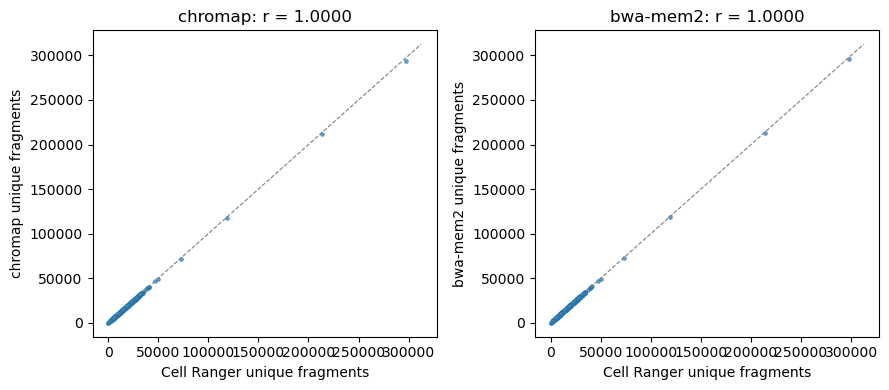

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
x = counts["Cell Ranger"].reindex(cr_cells).fillna(0)
for ax, k in zip(axes, ("chromap", "bwa-mem2")):
    y = counts[k].reindex(cr_cells).fillna(0)
    ax.scatter(x, y, s=6, alpha=0.6)
    lim = [0, max(x.max(), y.max()) * 1.05]
    ax.plot(lim, lim, color="grey", lw=0.8, ls="--")
    ax.set(xlabel="Cell Ranger unique fragments", ylabel=f"{k} unique fragments",
           title=f"{k}: r = {np.corrcoef(x, y)[0, 1]:.4f}")
fig.tight_layout()

**The same fragments?** For each cell, the Jaccard index of the exact
(chrom, start, end) sets. bwa-mem2 is the aligner inside Cell Ranger (as bwa), so it
reproduces most fragments base for base; chromap is a different aligner with its own
mapping-quality model, so more fragments differ at the margin (repeats near the MAPQ
cut-off, soft-clipped ends).

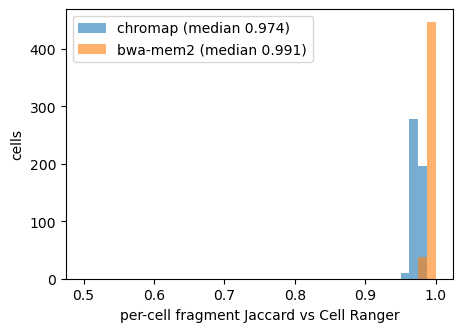

In [12]:
def keys(df):
    cid = df["chrom"].map({c: i for i, c in enumerate(NUCLEAR)}).to_numpy(np.int64)
    return (cid << 50) | (df["start"].to_numpy() << 21) | (df["end"] - df["start"]).to_numpy()

def by_cell(df):
    k = keys(df)
    return {c: np.unique(k[idx]) for c, idx in pd.Series(np.arange(len(df))).groupby(df["barcode"].to_numpy()).indices.items()}

cells_ref = by_cell(frags["Cell Ranger"])
jac = {}
for k in ("chromap", "bwa-mem2"):
    other = by_cell(frags[k])
    jac[k] = [np.intersect1d(cells_ref[c], other.get(c, []), assume_unique=True).size
              / np.union1d(cells_ref[c], other.get(c, [])).size for c in cr_cells]
fig, ax = plt.subplots(figsize=(5, 3.5))
for k, v in jac.items():
    ax.hist(v, bins=40, range=(0.5, 1), alpha=0.6, label=f"{k} (median {np.median(v):.3f})")
ax.set(xlabel="per-cell fragment Jaccard vs Cell Ranger", ylabel="cells")
ax.legend()

**Fragment length** shows the nucleosome ladder in all three files:

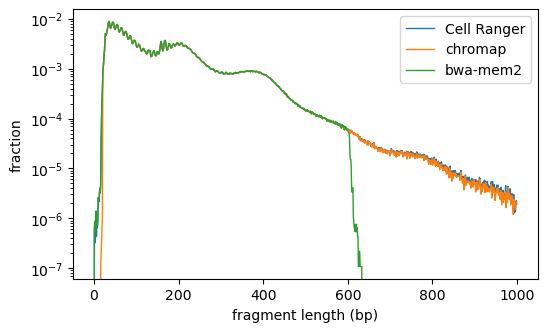

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for k, df in frags.items():
    sub = df[df["barcode"].isin(cr_cells)]
    h = np.bincount((sub["end"] - sub["start"]).clip(upper=1000), minlength=1001)[:1000]
    ax.plot(h / h.sum(), label=k, lw=1)
ax.set(xlabel="fragment length (bp)", ylabel="fraction", yscale="log")
ax.legend()

**TSS enrichment** per cell: Tn5 insertions within ±50 bp of a TSS per bp, over the
insertions per bp in the flanks 1.9–2 kb away.

In [14]:
tss = pd.read_csv(TSS_BED, sep="\t", header=None, usecols=[0, 1], names=["chrom", "pos"])
tss = {c: np.unique(g["pos"].to_numpy()) for c, g in tss[tss["chrom"].isin(NUCLEAR)].groupby("chrom")}

def tsse(df, cells):
    idx = {c: i for i, c in enumerate(cells)}
    df = df[df["barcode"].isin(idx)]
    center, flank = np.zeros(len(cells)), np.zeros(len(cells))
    for chrom, g in df.groupby("chrom"):
        T, b = tss[chrom], g["barcode"].map(idx).to_numpy()
        for pos in (g["start"].to_numpy(), g["end"].to_numpy() - 1):
            j = np.searchsorted(T, pos)
            d = np.minimum(np.abs(pos - T[np.clip(j - 1, 0, T.size - 1)]), np.abs(T[np.clip(j, 0, T.size - 1)] - pos))
            np.add.at(center, b[d <= 50], 1)
            np.add.at(flank, b[(d >= 1901) & (d <= 2000)], 1)
    return (center / 101) / ((flank + 1) / 200)

scores = pd.DataFrame({k: tsse(df, cr_cells) for k, df in frags.items()}, index=cr_cells)
print(scores.corr().round(4))
scores.median().round(2)

             Cell Ranger  chromap  bwa-mem2
Cell Ranger       1.0000   0.9880    0.9989
chromap           0.9880   1.0000    0.9877
bwa-mem2          0.9989   0.9877    1.0000


Cell Ranger    80.73
chromap        81.29
bwa-mem2       80.81
dtype: float64

## Downstream

The fragment files plug straight into the rest of Epione. For instance, the per-cell QC
of `epi.pp.import_fragments`:

In [15]:
sizes = dict(pd.read_csv(FASTA + ".fai", sep="\t", header=None, usecols=[0, 1]).values)
sizes = {c: int(sizes[c]) for c in NUCLEAR + ["chrM"]}
adata = epi.pp.import_fragments(str(res_chromap), chrom_sizes=sizes, min_num_fragments=1000)
adata

└─ scanning fastq_to_fragments/chromap/fragments.tsv.gz


  └─ imported 590 cells  (9,765,977 unique fragments)


AnnData object with n_obs × n_vars = 590 × 0
    obs: 'n_fragment', 'frac_dup', 'frac_mito'
    uns: 'files', 'reference_sequences'

In [16]:
adata.obs.describe().round(3)

,n_fragment,frac_dup,frac_mito
count,590.000,590.000,590.000
mean,16552.503,0.590,0.002
std,17935.874,0.147,0.011
min,1020.000,0.030,0.000
25%,6798.500,0.551,0.000
50%,15284.500,0.634,0.000
75%,23390.250,0.684,0.001
max,293940.000,0.825,0.246


## Other layouts

* **Multiome ATAC**: `chemistry="multiome"` with the ATAC version of the `737K-arc-v1`
  whitelist. Cell Ranger ARC reports ATAC fragments under the *gene-expression* barcode
  of the same gel bead; to get the same names pass both whitelists,
  `barcode_translation=(atac_whitelist, gex_whitelist)`: line *i* of one is line *i* of
  the other.
* **Barcode in an index file** (`bcl2fastq` without the 10x base mask: genomic `R1`/`R2`,
  barcode in `I2`): detected automatically when there is no `R3`.
* **Anything else**: `chemistry=epi.upstream.ReadLayout(read1="R1", read2="R2",
  barcode="I1", bc_start=0, bc_length=16, bc_orientation="auto")`.
* **A BAM you already have** (e.g. Cell Ranger's `possorted_bam.bam`):
  `epi.upstream.bam_to_fragments(bam, "fragments.tsv.gz", barcode_tag="CB")`.